In [1]:
import numpy as np
import pandas as pd
from pathlib import Path
from datetime import datetime
import torch

import sys
sys.path.append("../../tools")
import prepare as prep
import functions as func

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


In [2]:
import importlib
#importlib.reload(acht)


In [3]:
load_dir5 = Path(f"../../saved_models/swi_species_15fold/sp3to20_SS_transpt3_r13")
smodel = func.load_saved_model_SS(load_dir5, device)
spredictor = func.Predictor(smodel)
MaxNum = smodel["NumSpecies"]
featgam2 = MaxNum**2-MaxNum


c:\Users\HW\anaconda3\Lib\site-packages\sklearn\base.py:376: InconsistentVersionWarning: Trying to unpickle estimator StandardScaler from version 1.6.1 when using version 1.5.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


In [16]:
df = pd.read_csv("../Fig4/gamma5.csv")


In [ ]:
n_real = 10
sub_df = df[df["richness"]==n_real]
#sub_df = sub_df.sample(n=100, random_state=42)
#sub_df = sub_df[sub_df["density"]<0.33]
#sub_df = sub_df[(sub_df["density"]>=0.33) & (sub_df["density"]<0.66)]
sub_df = sub_df[sub_df["density"]>=0.66]
datasize = len(sub_df)
Xnum_pad = sub_df.iloc[:, :(MaxNum**2+MaxNum)].values
Xg, XA, Xd = prep.process_narray_X(Xnum_pad, MaxNum, featgam2, smodel["scaler_g"], smodel["scaler_d"])
swi_species = spredictor.predict_array_SS(Xnum_pad, device)


In [33]:
switch_in_mean = []
switch_out_mean = []
nonswitch_in_mean = []
nonswitch_out_mean = []
in_mean = []
out_mean = []

for i in range(datasize):

    # True species count of current sample
    n = n_real[i] if hasattr(n_real, "__len__") else n_real # If n_real is scalar, use directly; if array, index into it
    A = XA[i, :n, :n]
    y = swi_species[i, :n]

    # remove self-interaction
    A_no_self = A.copy()
    np.fill_diagonal(A_no_self, 0)

    threshold = 1e-8
    mask = np.abs(A_no_self) > threshold

    # in-degree
    # -> count nonzero entries along row
    indegree = np.sum(mask, axis=1)

    # out-degree
    # -> count nonzero entries along column
    outdegree = np.sum(mask, axis=0)

    # indegree = np.sum(A != 0, axis=1)
    # outdegree = np.sum(A != 0, axis=0)

    switch_mask = (y == 1)
    nonswitch_mask = (y == 0)

    # if np.sum(switch_mask) > 0:
    #     switch_in_mean.append(indegree[switch_mask].mean())
    #     switch_out_mean.append(outdegree[switch_mask].mean())
    # if np.sum(nonswitch_mask) > 0:
    #     nonswitch_in_mean.append(indegree[nonswitch_mask].mean())
    #     nonswitch_out_mean.append(outdegree[nonswitch_mask].mean())

    if np.sum(switch_mask) > 0:
        switch_in_mean.append(indegree[switch_mask])
        switch_out_mean.append(outdegree[switch_mask])
    if np.sum(nonswitch_mask) > 0:
        nonswitch_in_mean.append(indegree[nonswitch_mask])
        nonswitch_out_mean.append(outdegree[nonswitch_mask])
    in_mean.append(indegree)
    out_mean.append(outdegree)


switch_in_mean = np.concatenate(switch_in_mean)
switch_out_mean = np.concatenate(switch_out_mean)
nonswitch_in_mean = np.concatenate(nonswitch_in_mean)
nonswitch_out_mean = np.concatenate(nonswitch_out_mean)
in_mean = np.concatenate(in_mean)
out_mean = np.concatenate(out_mean)

# switch_in_mean = np.array(switch_in_mean)
# switch_out_mean = np.array(switch_out_mean)
# nonswitch_in_mean = np.array(nonswitch_in_mean)
# nonswitch_out_mean = np.array(nonswitch_out_mean)


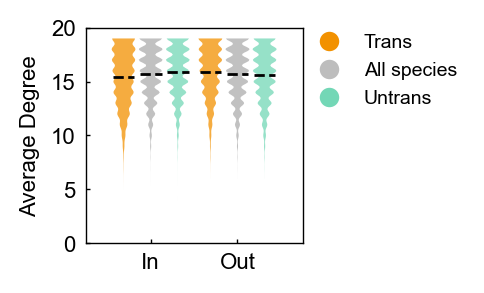

In [34]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D

plt.rcParams.update({
    'font.family': 'Arial',
    'font.size': 8,
    'axes.labelsize': 8, # axis labels (text)
    'axes.titlesize': 9,
    'axes.linewidth': 0.5, # axis border line width
    'legend.fontsize': 7, # legend (legend content, not legend title)
    'xtick.major.width': 0.5, # tick line width
    'ytick.major.width': 0.5,
    'xtick.major.size': 1.5, # tick line length (1.5 is relatively short)
    'ytick.major.size': 1.5,
    'xtick.labelsize': 8, # x-axis tick labels (numbers)
    'ytick.labelsize': 8,
    'mathtext.fontset': 'stix', # make math formulas more consistent with Arial

    'pdf.fonttype': 42, # preserve Arial font when exporting to PDF
    'ps.fonttype': 42
})

fig, ax = plt.subplots(figsize=(1.4, 1.4), dpi=200)

# =========================================================
# Data
# =========================================================
data = [
    switch_in_mean,
    in_mean,
    nonswitch_in_mean,

    switch_out_mean,
    out_mean,
    nonswitch_out_mean
]

positions = [
    -0.65, -0.4, -0.15,
     0.15,  0.4,  0.65
]

colors = [
    "#F29100",
    "#ADADAD",
    "#73D7B6",
    "#F29100",
    "#ADADAD",
    "#73D7B6"
]

# violin
vp = plt.violinplot(
    data,
    positions=positions,
    widths=0.22,
    showmeans=False,
    showmedians=False,
    showextrema=False
)

# violin color
for body, color in zip(vp['bodies'], colors):

    body.set_facecolor(color)
    body.set_edgecolor('none')
    body.set_alpha(0.75)

# mean line
means = [np.mean(d) for d in data]

for x, m in zip(positions, means):

    plt.hlines(
        m,
        x - 0.1,
        x + 0.1,
        color='black',
        linewidth=1,
        linestyle='--',
        zorder=5
    )

# x-axis
plt.xticks(
    [-0.4, 0.4],
    ['In', 'Out']
)

plt.ylabel("Average Degree")

legend_elements = [

    Line2D(
        [0], [0],
        marker='o',
        color='w',
        label='Trans',
        markerfacecolor='#F29100',
        markersize=8
    ),

    Line2D(
        [0], [0],
        marker='o',
        color='w',
        label='All species',
        markerfacecolor='#BDBDBD',
        markersize=8
    ),

    Line2D(
        [0], [0],
        marker='o',
        color='w',
        label='Untrans',
        markerfacecolor='#73D7B6',
        markersize=8
    )
]

plt.legend(
    handles=legend_elements,
    frameon=False,
    loc='center left',
    bbox_to_anchor=(0.95, 0.8),
    ncol=1,
)

# for spine in ax.spines.values():
#     spine.set_linewidth(1.1)

ax.tick_params(direction="in")
plt.grid(False)

plt.xlim(-1, 1)
plt.ylim(0, n_real)

plt.savefig(f"switch_violin_{datetime.now().strftime('%Y%m%d_%H%M%S')}.pdf", dpi=1000, bbox_inches='tight', transparent=True, )
plt.show()
